# 03 · Presupuesto de etiquetas del destino

**Pregunta.** Partiendo de un modelo entrenado en otro sistema (fuente), ¿cuántas etiquetas expertas del sistema nuevo (destino) hacen falta para acercarse al modelo local?

Por cada destino (siempre por separado) y cada n (etiquetas del destino, total, no por clase):
- **fuente + azar**: 100 por clase de la fuente más n eventos del destino al azar;
- **fuente + activo**: igual, pero los n se eligen por aprendizaje activo (menor margen |p(LP)−0,5|);
- **solo destino**: n eventos del destino al azar, sin la fuente;
- **modelo local**: hasta 100 por clase del destino (techo, línea horizontal).

Las líneas son la mediana sobre fuentes del Gm medio de las repeticiones; la banda es el rango intercuartil sobre fuentes. Fuente: `../resultados/presupuesto_resumen.csv` (generado con `scripts/resumir_presupuesto.py`).

> **Resultados provisorios**: el cálculo seguía corriendo cuando se generó el resumen; faltan destinos y algunos pares.
>
> **Advertencia**: XGBoost "solo destino" con n = 10 da Gm ≈ 0 por un artefacto de configuración (con tan pocos eventos el modelo predice una sola clase); se corregirá. No es un resultado.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
pd.set_option("display.width", 160, "display.max_columns", 30)
DATOS, RES = Path("../datos"), Path("../resultados")
r = pd.read_csv(RES / "presupuesto_resumen.csv")
print(r.groupby("destino").fuente.nunique().rename("n_fuentes").to_string())

destino
Alaska              9
Cascade             9
Copahue             9
Hawái               9
Hudson              9
Laguna del Maule    5


In [2]:
ESTILO = {"azar": ("fuente + azar", "#3b75af", "-"), "activo": ("fuente + activo", "#c0392b", "-"),
          "solo_destino": ("solo destino", "#555555", "--")}
NOMBRE = {"log": "Regresión logística", "xgb": "XGBoost", "tabpfn": "TabPFN"}
destinos = sorted(r.destino.unique())

def curvas(modelo):
    g = r[r.modelo == modelo]
    fig, ejes = plt.subplots(2, int(np.ceil(len(destinos) / 2)), figsize=(12, 6), sharey=True)
    for ax, dst in zip(ejes.flat, destinos):
        h = g[g.destino == dst]
        for sel, (lab, col, ls) in ESTILO.items():
            q = h[h.seleccion == sel].groupby("n").gm.quantile([.25, .5, .75]).unstack()
            if q.empty:
                continue
            ax.plot(q.index, q[.5], ls, color=col, marker="o", ms=3, label=lab)
            ax.fill_between(q.index, q[.25], q[.75], color=col, alpha=.15)
        loc = h[h.seleccion == "local"].gm.median()
        if np.isfinite(loc):
            ax.axhline(loc, color="g", lw=1, ls=":", label="modelo local")
        ax.set_xscale("symlog", linthresh=10); ax.set_xlim(-0.5, 230); ax.set_xticks([0, 10, 20, 50, 100, 200])
        ax.set_xticklabels([0, 10, 20, 50, 100, 200])
        ax.set_title(f"{dst} ({h.fuente.nunique()} fuentes)"); ax.grid(alpha=.3); ax.set_ylim(0, 1)
    for ax in ejes.flat[len(destinos):]:
        ax.axis("off")
    for ax in ejes[-1]:
        ax.set_xlabel("n etiquetas del destino")
    for ax in ejes[:, 0]:
        ax.set_ylabel("Gm")
    ejes.flat[0].legend(fontsize=7, loc="lower right")
    fig.suptitle(NOMBRE[modelo]); fig.tight_layout()

## Regresión logística

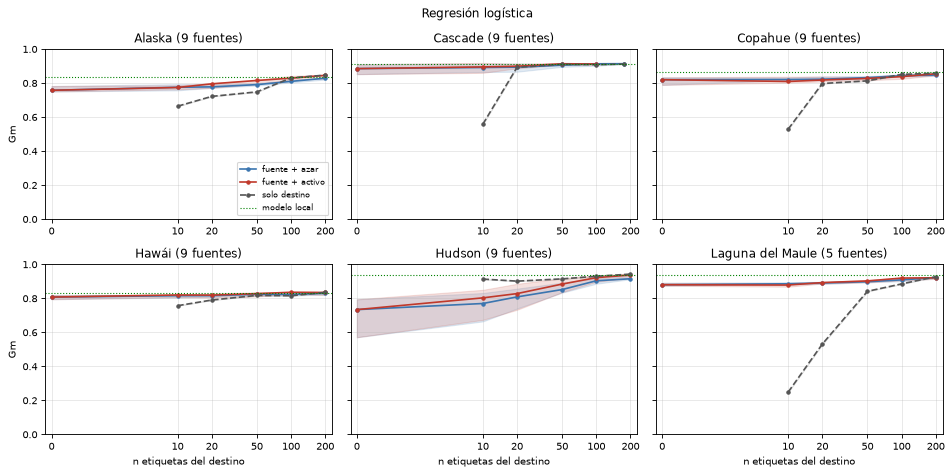

In [3]:
curvas("log")

## XGBoost

(Recordar el artefacto de "solo destino" en n = 10.)

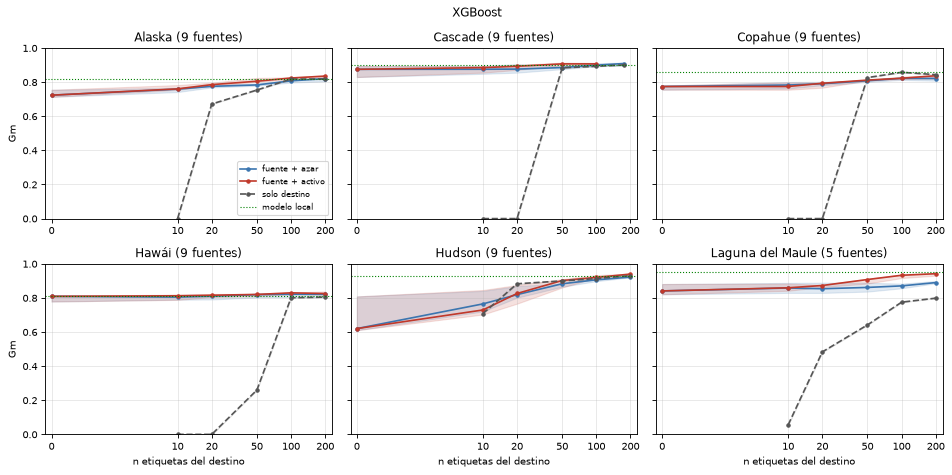

In [4]:
curvas("xgb")

## TabPFN

Solo selección al azar (sin aprendizaje activo).

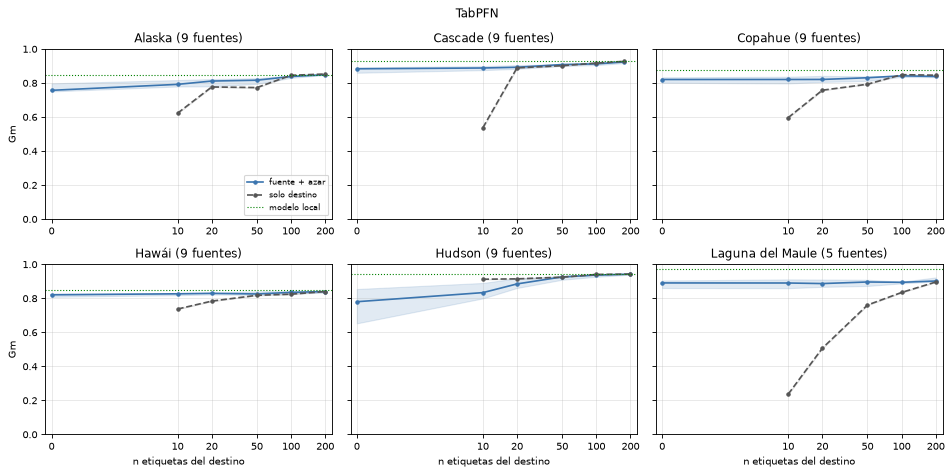

In [5]:
curvas("tabpfn")

## Tabla: mediana sobre fuentes del Gm, por destino, modelo, selección y n

In [6]:
t = (r[r.seleccion != "local"].groupby(["destino", "modelo", "seleccion", "n"]).gm.median()
     .unstack("n").round(3))
t

n                                       0      10     20     50     100    174    200
destino          modelo seleccion                                                    
Alaska           log    activo        0.758  0.774  0.796  0.815  0.829    NaN  0.846
                        azar          0.758  0.775  0.778  0.791  0.810    NaN  0.829
                        solo_destino    NaN  0.664  0.722  0.748  0.830    NaN  0.847
                 tabpfn azar          0.757  0.792  0.811  0.816  0.838    NaN  0.848
                        solo_destino    NaN  0.622  0.777  0.773  0.845    NaN  0.853
                 xgb    activo        0.724  0.761  0.786  0.806  0.824    NaN  0.836
                        azar          0.724  0.759  0.776  0.784  0.808    NaN  0.821
                        solo_destino    NaN  0.000  0.672  0.754  0.818    NaN  0.818
Cascade          log    activo        0.885  0.895  0.899  0.914  0.912    NaN    NaN
                        azar          0.885  0.892  0.894  0.905  0.913  0.914    NaN
                        solo_destino    NaN  0.558  0.893  0.911  0.908  0.912    NaN
                 tabpfn azar          0.883  0.888  0.892  0.908  0.912  0.923    NaN
                        solo_destino    NaN  0.537  0.889  0.902  0.917  0.927    NaN
                 xgb    activo        0.875  0.885  0.893  0.907  0.907    NaN    NaN
                        azar          0.875  0.876  0.877  0.886  0.900  0.909    NaN
                        solo_destino    NaN  0.000  0.000  0.884  0.893  0.901    NaN
Copahue          log    activo        0.820  0.809  0.818  0.827  0.838    NaN  0.855
                        azar          0.820  0.821  0.823  0.832  0.843    NaN  0.847
                        solo_destino    NaN  0.529  0.797  0.813  0.851    NaN  0.858
                 tabpfn azar          0.820  0.820  0.821  0.831  0.842    NaN  0.838
                        solo_destino    NaN  0.596  0.757  0.793  0.849    NaN  0.846
                 xgb    activo        0.775  0.775  0.794  0.812  0.823    NaN  0.838
                        azar          0.775  0.783  0.791  0.808  0.823    NaN  0.821
                        solo_destino    NaN  0.000  0.000  0.827  0.858    NaN  0.844
Hawái            log    activo        0.807  0.820  0.819  0.828  0.836    NaN  0.835
                        azar          0.807  0.816  0.816  0.824  0.823    NaN  0.830
                        solo_destino    NaN  0.757  0.790  0.817  0.815    NaN  0.835
                 tabpfn azar          0.821  0.827  0.829  0.825  0.835    NaN  0.840
                        solo_destino    NaN  0.737  0.784  0.818  0.824    NaN  0.840
                 xgb    activo        0.809  0.813  0.816  0.821  0.830    NaN  0.826
                        azar          0.809  0.805  0.810  0.819  0.822    NaN  0.821
                        solo_destino    NaN  0.000  0.000  0.260  0.801    NaN  0.805
Hudson           log    activo        0.734  0.803  0.828  0.884  0.922    NaN  0.937
                        azar          0.734  0.770  0.808  0.852  0.903    NaN  0.915
                        solo_destino    NaN  0.913  0.901  0.915  0.930    NaN  0.943
                 tabpfn azar          0.780  0.833  0.885  0.926  0.937    NaN  0.942
                        solo_destino    NaN  0.912  0.914  0.924  0.940    NaN  0.942
                 xgb    activo        0.620  0.729  0.826  0.902  0.920    NaN  0.940
                        azar          0.620  0.765  0.819  0.883  0.906    NaN  0.922
                        solo_destino    NaN  0.708  0.883  0.900  0.914    NaN  0.931
Laguna del Maule log    activo        0.880  0.878  0.893  0.902  0.919    NaN  0.921
                        azar          0.880  0.886  0.890  0.898  0.909    NaN  0.922
                        solo_destino    NaN  0.249  0.531  0.841  0.885    NaN  0.927
                 tabpfn azar          0.890  0.890  0.887  0.896  0.894    NaN  0.902
                        solo_destino    NaN 